# 06 — Regressão: empregados pela receita e de onde vem o passivo

**Para que serve este notebook.** Duas perguntas que a escada do projeto (`docs/plano_projeto.md`) deixa em aberto:

- **(a)** dá para **estimar quantos empregados CLT** um cartório tem só pela receita e pelas atribuições? Em Minas Gerais o CNJ informa essa contagem, mas em outros estados não. Se o modelo funcionar em MG, ele pode levar a escada para outros estados (degraus 2 e 4).
- **(b)** o passivo trabalhista de um cartório (o custo de demitir todos os empregados, degrau 4) depende de **quantos** empregados ele tem, de **quanto** eles ganham e de **há quanto tempo** estão lá. **Quanto da diferença de passivo entre cartórios vem de cada uma dessas três partes?**

**O que é uma regressão.** Um modelo que estima um número (o "alvo", aqui os empregados ou o passivo) a partir de outros números (as "variáveis", aqui a receita, as atribuições, o salário e o tempo de casa). Ele aprende a relação nos dados e depois pode prever o alvo onde ele não é conhecido.

**Como o método foi escolhido.** Antes deste notebook, o teste **T1** (`docs/qa/analises/testes_metodos.md`) comparou sete métodos para a parte (a) e escolheu a **floresta aleatória**, com a regressão de **Poisson** como versão fácil de explicar. Aqui usamos o vencedor, comparamos com a mesma referência do teste e conferimos se o resultado se repete. A semente do sorteio é a de `config/analise.yaml` (20261022); o teste usou 42, então pequenas diferenças são esperadas.

**Termos usados** (explicados com exemplo onde aparecem pela primeira vez): erro absoluto médio (MAE), R², validação com a região de fora, floresta aleatória, regressão de Poisson, resíduo, logaritmo (log), elasticidade, variância, divisão de Shapley.

**Dados:** banco do pipeline (carga de 19/10/2026): receita média de 2025 e CLT declarados ao CNJ (Justiça Aberta), regiões do IBGE, vínculos da RAIS 2025 e o passivo do modelo (premissas v2, nível base). Este notebook **não muda** nenhum dos 10 números do painel. Os gráficos também vão em PNG para `docs/qa/analises/`.

In [1]:
import json
import sys
from pathlib import Path

raiz = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import estado
from src.analise import config, dados, graficos as g, regressao as rg
from src.model.distribuicao import preparar_vinculos
from src.model.passivo import passivo_por_vinculo
from src.model.premissas import resolver
from src.notebooks import conectar

g.estilo()
SEMENTE = config()["semente"]
con = conectar()
sv = dados.serventias(con)
t1 = json.loads((raiz / "docs/qa/analises/testes_metodos_resultados.json").read_text(encoding="utf-8"))
print(f"{g.num(len(sv))} serventias ativas; {g.num(sv.clt.sum())} empregados CLT declarados ao CNJ; "
      f"passivo de todas: {g.reais(sv.passivo.sum())}. Semente: {SEMENTE}.")

2.525 serventias ativas; 12.134 empregados CLT declarados ao CNJ; passivo de todas: R$ 311,9 mi. Semente: 20261022.


A linha acima reproduz os números 1, 2 e 4 do painel (2.525 serventias, 12.134 empregados CLT e R$ 311,9 mi de passivo), o que confirma que estamos olhando os mesmos dados.

## Parte (a) — Empregados CLT a partir da receita (teste T1)

### 1. Os dados do modelo

**A pergunta.** Quais cartórios entram no modelo?

**O método.** Entram as serventias com **receita de referência de 2025 maior que zero** (a média dos semestres de 2025, a mesma que define a classe), **CLT informado** ao CNJ e **região intermediária** conhecida. É o mesmo recorte do teste T1. As variáveis são: o **log da receita**, o **número de atribuições** e uma marca "tem / não tem" para cada uma das seis atribuições (Notas, Registro Civil, Imóveis, Títulos e Documentos, Pessoas Jurídicas, Protesto).

Por que o **log** da receita: a receita vai de alguns milhares a centenas de milhões de reais. No log, cada passo é "multiplicar por um fator" (log natural: cada unidade = receita × 2,7), e um cartório com R$ 10 milhões não "pesa" mil vezes mais que um com R$ 10 mil na hora de ajustar o modelo.

In [2]:
base = rg.base_clt(sv)
fora = sv[~sv.cns.isin(base.cns)]
print(f"Serventias no modelo: {g.num(len(base))} (as mesmas {t1['T1_empregados_pela_receita']['n']} do teste T1); "
      f"média de {g.num(base.clt.mean(), 2)} CLT por serventia; {base.regiao_intermediaria.nunique()} regiões intermediárias.")
print(f"Fora do modelo: {g.num(len(fora))} serventias ({g.num((fora.receita_ref.fillna(0) <= 0).sum())} sem receita "
      f"válida em 2025, {g.num(fora.clt.isna().sum())} sem CLT informado).")
display(g.tabela(base.groupby("regiao_intermediaria").agg(serventias=("cns", "size"), clt=("clt", "sum"),
                                                          receita_mediana=("receita_ref", "median")).reset_index(),
                 {"serventias": "int", "clt": "int", "receita_mediana": "reais"}))

Serventias no modelo: 2.444 (as mesmas 2444 do teste T1); média de 4,85 CLT por serventia; 13 regiões intermediárias.
Fora do modelo: 81 serventias (78 sem receita válida em 2025, 4 sem CLT informado).


,regiao_intermediaria,serventias,clt,receita_mediana
0,Barbacena,127,438,"R$ 256,3 mil"
1,Belo Horizonte,317,2.991,"R$ 517,7 mil"
2,Divinópolis,180,913,"R$ 547,6 mil"
3,Governador Valadares,146,487,"R$ 193,4 mil"
4,Ipatinga,120,483,"R$ 283,9 mil"
5,Juiz de Fora,391,1.274,"R$ 209,9 mil"
6,Montes Claros,208,761,"R$ 132,1 mil"
7,Patos de Minas,128,629,"R$ 506,8 mil"
8,Pouso Alegre,209,858,"R$ 417,5 mil"
9,Teófilo Otoni,206,531,"R$ 149,6 mil"


### 2. O modelo e a referência

**A pergunta.** A floresta aleatória acerta mais que um "chute" simples?

**O método.**
- **Referência (o chute):** dividir os cartórios de treino em 10 faixas de receita com o mesmo número de cartórios (**decis**) e prever, para um cartório novo, a **mediana** de CLT da faixa dele. Exemplo: se o cartório arrecada R$ 200 mil e, na faixa de R$ 150 a 250 mil, o cartório do meio tem 2 CLT, a previsão é 2.
- **Floresta aleatória (vencedor do T1):** uma **árvore de decisão** faz perguntas em sequência ("a receita passa de R$ 800 mil? tem Registro de Imóveis?") e, no fim de cada caminho, prevê a média de CLT dos cartórios de treino que chegaram ali. A **floresta** treina 400 árvores, cada uma num sorteio diferente dos cartórios, e tira a média delas. Isso pega relações curvas e combinações de atribuições sem precisar dizer a fórmula antes. Cada "folha" precisa de pelo menos 5 cartórios, para não decorar casos isolados.
- **Poisson (versão explicável):** supõe que o log do CLT esperado é uma soma ponderada das variáveis. Cada peso vira um fator que multiplica o CLT (seção 5).

**Validação: a região de fora.** O uso real é prever um lugar que o modelo **nunca viu** (outro estado). Para imitar isso, cada uma das **13 regiões intermediárias** de MG fica de fora uma vez: o modelo treina nas outras 12 e prevê a que ficou de fora. Assim, toda previsão abaixo é de um cartório que o modelo não viu, numa região que ele não viu.

**As métricas.**
- **MAE (erro absoluto médio):** a média de |declarado − previsto|. Exemplo: se o modelo prevê 3, 5 e 2 para cartórios que têm 4, 5 e 0, os erros são 1, 0 e 2, e o MAE é 1. É o indicador que decidiu o T1.
- **RMSE:** como o MAE, mas eleva os erros ao quadrado antes da média; pesa mais os erros grandes.
- **R²:** quanto da diferença de CLT entre cartórios o modelo explica: 0 = nada (tanto faz prever a média), 1 = tudo.
- **Erro do total:** para cada região de fora, (soma prevista − soma declarada) ÷ soma declarada. O passivo usa o **total**, então esse erro importa para levar o modelo a outro estado.

**Por que este método.** No T1, a floresta teve o menor MAE com a região de fora (1,86, contra 2,34 da referência), à frente de gradient boosting, Poisson, binomial negativa, regressão log-log e razão CLT ÷ receita.

,método,MAE,RMSE,R2,erro_total_medio_pct,MAE no teste T1,erro do total no T1 (%),MAE vs referência
0,Floresta aleatória,"1,86","4,35","0,75","9,3","1,86","9,3","-20,2%"
1,Poisson (GLM),"1,93","5,39","0,61","12,0","1,93","12,0","-17,5%"
2,Referência: mediana por faixa de receita,"2,34","6,63","0,41","16,2","2,34","16,2","0,0%"


Floresta: MAE 1,86 empregado por serventia (20,2% menor que a referência), R² 0,75; erro médio do total de uma região não vista: 9,3%.


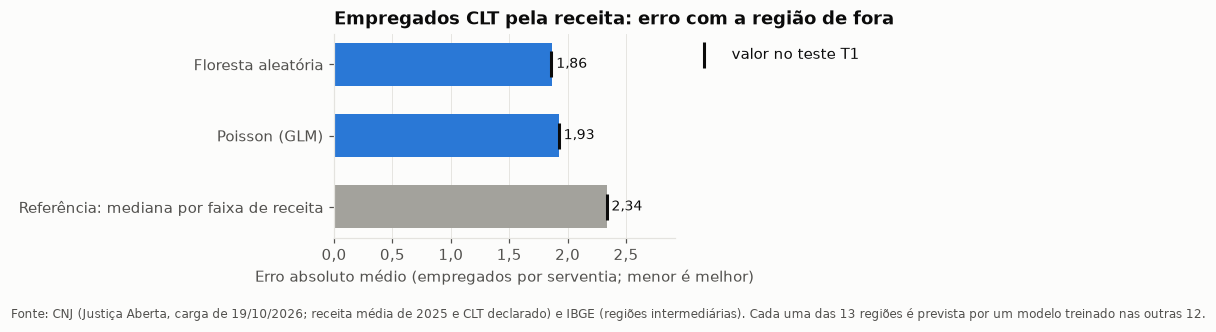

In [3]:
prev, metr, por_regiao = rg.validar_grupo_fora(base, rg.METODOS_CLT)
teste = {r["metodo"]: r for r in t1["T1_empregados_pela_receita"]["tabela"]}
nomes_teste = {"Floresta aleatória": "Floresta aleatória", "Poisson (GLM)": "Poisson (GLM)",
               "Referência: mediana por faixa de receita": "referência: mediana por decil de receita"}
metr["MAE no teste T1"] = [teste[nomes_teste[m]]["MAE_regiao_fora"] for m in metr.index]
metr["erro do total no T1 (%)"] = [teste[nomes_teste[m]]["erro_total_regiao_fora_pct"] for m in metr.index]
ref = metr.loc["Referência: mediana por faixa de receita", "MAE"]
metr["MAE vs referência"] = metr["MAE"] / ref - 1
display(g.tabela(metr.reset_index(names="método"),
                 {"MAE": "num2", "RMSE": "num2", "R2": "num2", "erro_total_medio_pct": "num1", "MAE no teste T1": "num2",
                  "erro do total no T1 (%)": "num1", "MAE vs referência": "pct"}))
rf = metr.loc["Floresta aleatória"]
print(f"Floresta: MAE {g.num(rf.MAE, 2)} empregado por serventia ({g.pct(-rf['MAE vs referência'])} menor que a referência), "
      f"R² {g.num(rf.R2, 2)}; erro médio do total de uma região não vista: {g.num(rf.erro_total_medio_pct, 1)}%.")

fig, ax = plt.subplots(figsize=(8, 2.8))
ordem = metr.sort_values("MAE", ascending=False)
cores = [g.CINZA if m.startswith("Referência") else g.AZUL["medio"] for m in ordem.index]
barras = ax.barh(ordem.index, ordem.MAE, color=cores, height=0.6)
ax.bar_label(barras, [g.num(v, 2) for v in ordem.MAE], padding=3, fontsize=9)
ax.scatter(ordem["MAE no teste T1"], range(len(ordem)), marker="|", s=300, color=g.TEXTO, zorder=3,
           label="valor no teste T1")
ax.set_xlabel("Erro absoluto médio (empregados por serventia; menor é melhor)")
ax.set_xlim(0, ordem.MAE.max() * 1.25)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: g.num(v, 1)))
ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("Empregados CLT pela receita: erro com a região de fora")
fig.tight_layout()
g.nota(fig, "Fonte: CNJ (Justiça Aberta, carga de 19/10/2026; receita média de 2025 e CLT declarado) e IBGE (regiões "
            "intermediárias). Cada uma das 13 regiões é prevista por um modelo treinado nas outras 12.")
g.salvar(fig, "06_clt_erro_por_metodo")
plt.show()

**Como ler.** Barras menores são melhores. O traço preto em cada barra é o valor do mesmo método no teste T1.

**O que encontramos.**
- A **floresta** erra em média **1,86 empregado por serventia** quando a região inteira ficou fora do treino: **20% menos que a referência** (2,34). Ela explica **75%** da diferença de CLT entre cartórios (R² 0,75, contra 0,41 da referência).
- O **Poisson** fica perto (1,93), mas erra mais nos cartórios grandes (RMSE 5,39 contra 4,35).
- **Bate com o teste T1:** MAE, R² e erro do total são os mesmos do teste nas casas mostradas (1,86; 0,75; 9,3%). A semente diferente (20261022 em vez de 42) só mexe nas casas seguintes.

**O que significa para o Prov. 227.** A receita e as atribuições, que o CNJ publica para todos os estados, bastam para estimar o número de empregados de cada cartório com um erro típico de um a dois empregados. É o que permite levar o degrau 2 da escada (e, com ele, o passivo) a estados sem a contagem do CNJ.

**Limitações.** O teste é dentro de MG: outro estado pode ter outra relação entre receita e empregados (tabela de emolumentos, salários, costume de terceirizar). Antes de usar fora de MG, validar num estado que tenha a contagem.

### 3. Onde a floresta erra (resíduos)

**A pergunta.** O erro é parecido em todos os cartórios, ou o modelo erra mais em algum tipo?

**O método.** O **resíduo** é declarado − previsto: positivo quando o cartório tem mais CLT do que a receita sugere, negativo quando tem menos. À esquerda, cada ponto é um cartório (eixos em escala log, com o zero incluído); se o modelo fosse perfeito, todos ficariam na linha laranja. À direita, o resíduo pela receita, com a mediana do resíduo em cada decil de receita (a linha preta): se ela fica longe do zero numa faixa, o modelo erra sempre para o mesmo lado ali (**viés**).

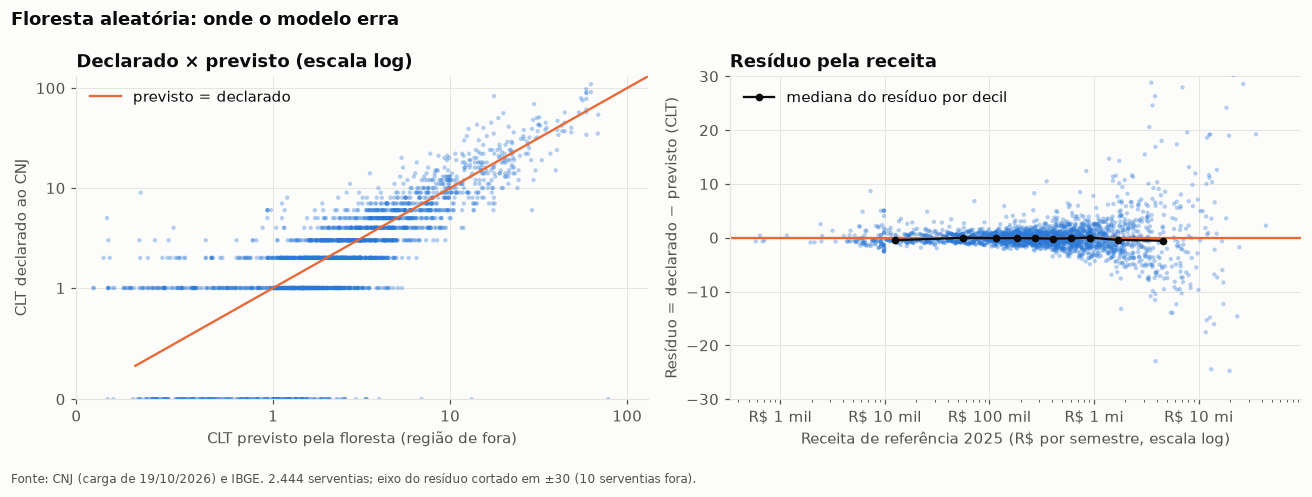

Erro típico (mediana do erro absoluto): 0,9 CLT; 90% das serventias erram até 3,7.
Resíduo mediano no decil de receita mais baixo: -0,45; no mais alto: -0,55.
Os 5 maiores resíduos positivos (mais CLT do que a receita sugere):


,cns,municipio,receita_ref,clt,previsto
131,033118,Belo Horizonte,"R$ 5,4 mi",83,"17,7"
46,032136,Uberlândia,"R$ 42,2 mi",109,"62,4"
2132,058412,Belo Horizonte,"R$ 8,9 mi",69,"29,8"
45,032128,Belo Horizonte,"R$ 24,9 mi",97,"58,8"
890,042556,Belo Horizonte,"R$ 6,7 mi",56,"20,0"


In [4]:
base["previsto"] = prev["Floresta aleatória"]
base["residuo"] = base.clt - base.previsto
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.scatter(base.previsto, base.clt, s=8, alpha=0.35, color=g.AZUL["medio"], edgecolor="none")
lim = [0.3, base[["clt", "previsto"]].max().max() * 1.2]
ax.plot(lim, lim, color=g.CORES[1], linewidth=1.5, label="previsto = declarado")
ax.set_xscale("symlog", linthresh=1); ax.set_yscale("symlog", linthresh=1)
ax.set_xlim(0, lim[1]); ax.set_ylim(0, lim[1])
for a in (ax.xaxis, ax.yaxis):
    a.set_major_formatter(plt.FuncFormatter(lambda v, _: g.num(v)))
ax.set_xlabel("CLT previsto pela floresta (região de fora)")
ax.set_ylabel("CLT declarado ao CNJ")
ax.legend(loc="upper left")
ax.set_title("Declarado × previsto (escala log)")
ax = axes[1]
ax.scatter(base.receita_ref, base.residuo, s=8, alpha=0.35, color=g.AZUL["medio"], edgecolor="none")
ax.axhline(0, color=g.CORES[1], linewidth=1.5)
faixa = pd.qcut(np.log(base.receita_ref), 10)
med = base.groupby(faixa, observed=True).agg(x=("receita_ref", "median"), y=("residuo", "median"))
ax.plot(med.x, med.y, color=g.TEXTO, marker="o", markersize=4, linewidth=1.5, label="mediana do resíduo por decil")
ax.set_xscale("log")
g.eixo_reais(ax, "x")
ax.set_ylim(-30, 30)
ax.set_xlabel("Receita de referência 2025 (R$ por semestre, escala log)")
ax.set_ylabel("Resíduo = declarado − previsto (CLT)")
ax.legend(loc="upper left")
ax.set_title("Resíduo pela receita")
fig.suptitle("Floresta aleatória: onde o modelo erra", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
g.nota(fig, f"Fonte: CNJ (carga de 19/10/2026) e IBGE. {g.num(len(base))} serventias; eixo do resíduo cortado em ±30 "
            f"({g.num((base.residuo.abs() > 30).sum())} serventias fora).")
g.salvar(fig, "06_clt_declarado_x_previsto")
plt.show()

q = base.residuo.abs().quantile([0.5, 0.9])
print(f"Erro típico (mediana do erro absoluto): {g.num(q[0.5], 1)} CLT; 90% das serventias erram até {g.num(q[0.9], 1)}.")
print(f"Resíduo mediano no decil de receita mais baixo: {g.num(med.y.iloc[0], 2)}; no mais alto: {g.num(med.y.iloc[-1], 2)}.")
grandes = base.nlargest(5, "residuo")[["cns", "municipio", "receita_ref", "clt", "previsto"]]
print("Os 5 maiores resíduos positivos (mais CLT do que a receita sugere):")
display(g.tabela(grandes, {"receita_ref": "reais", "clt": "int", "previsto": "num1"}))

**Como ler.** À esquerda, os pontos se espalham em volta da linha laranja em todos os tamanhos; as faixas horizontais aparecem porque o CLT declarado é um número inteiro (0, 1, 2...). À direita, a mediana do resíduo fica perto de zero em todos os decis de receita.

**O que encontramos.**
- O erro **típico** é pequeno: metade das serventias erra no máximo **0,9 empregado**; 90% erram até **3,7**.
- **Não há viés por tamanho:** a mediana do resíduo fica entre −0,55 e +0,02 empregado em todos os decis. Ela é levemente negativa porque a floresta prevê a **média** de CLT de cartórios parecidos, e a média fica acima da mediana quando poucos cartórios têm muito mais empregados que os outros.
- O erro **cresce com a receita** (o "funil" à direita): acima de R$ 1 milhão por semestre, o resíduo passa de ±10 empregados em vários cartórios. Os maiores resíduos positivos são cartórios grandes da capital e de Uberlândia com 36 a 65 empregados a mais do que a receita sugere.
- **Zero CLT:** no recorte, 285 serventias declaram zero empregado, 229 delas vagas (a linha de pontos no zero, à esquerda). A floresta prevê para elas, na mediana, 0,9 empregado.

**O que significa para o Prov. 227.** Para os cartórios pequenos e médios, o modelo serve. Para os grandes, que concentram o passivo (notebook 02: os 10% maiores têm 61%), o erro de um cartório pode ser de dezenas de empregados; no total, esses erros se compensam em parte (seção 4).

**Limitações.** O modelo não sabe se o cartório está vago (essa variável foi deixada de fora de propósito, porque não serve para prever outro estado); por isso erra nos vagos com zero CLT.

### 4. O total de uma região que o modelo não viu

**A pergunta.** Se usarmos o modelo para estimar o total de empregados de um lugar novo, quanto ele erra?

**O método.** Para cada região de fora, somamos as previsões dos cartórios dela e comparamos com a soma declarada ao CNJ. O teste T1 exigia erro de até 5% no total; nenhum método cumpriu, e a regra de uso ficou: **publicar o total com ±10%** (`config/analise.yaml`, `margem_total`). A faixa cinza do gráfico é essa margem.

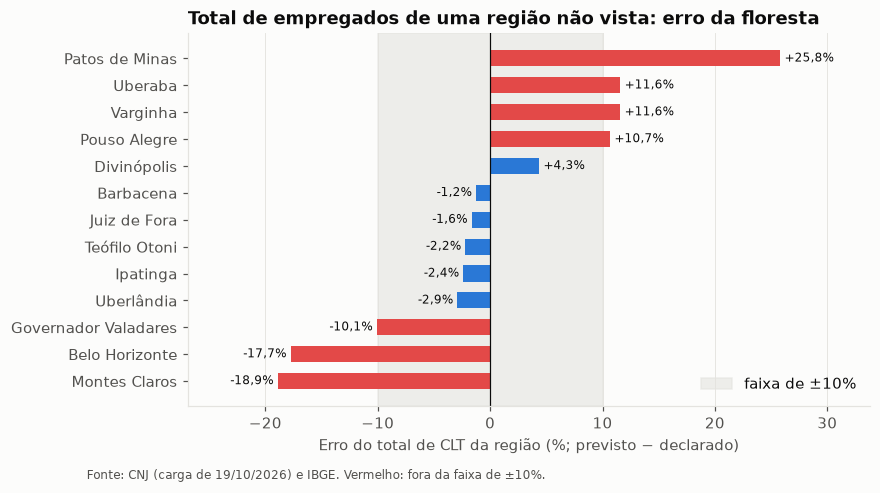

Regiões fora de ±10%: 7 de 13; erro médio 9,3%, maior 25,8%.
MG inteiro (soma das 13 regiões previstas de fora): previsto 11.562 CLT, faixa 10.405 – 12.718; declarado 11.864 (diferença de -2,5%).


In [5]:
pr = por_regiao[por_regiao.metodo == "Floresta aleatória"].sort_values("erro_total_pct")
margem = config()["regressao"]["margem_total"]
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.axvspan(-100 * margem, 100 * margem, color=g.GRADE, alpha=0.6, label=f"faixa de ±{g.num(100 * margem)}%")
cores = [g.CORES[7] if abs(e) > 100 * margem else g.AZUL["medio"] for e in pr.erro_total_pct]
barras = ax.barh(pr.regiao_intermediaria, pr.erro_total_pct, color=cores, height=0.6)
ax.bar_label(barras, [f"{v:+.1f}%".replace(".", ",") for v in pr.erro_total_pct], padding=3, fontsize=8)
ax.axvline(0, color=g.TEXTO, linewidth=0.8)
ax.set_xlim(pr.erro_total_pct.min() - 8, pr.erro_total_pct.max() + 8)
ax.set_xlabel("Erro do total de CLT da região (%; previsto − declarado)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Total de empregados de uma região não vista: erro da floresta")
g.nota(fig, "Fonte: CNJ (carga de 19/10/2026) e IBGE. Vermelho: fora da faixa de ±10%.")
g.salvar(fig, "06_clt_erro_total_por_regiao")
plt.show()

total_prev, total_real = pr.previsto.sum(), pr.real.sum()
inf, sup = rg.total_com_margem(total_prev)
print(f"Regiões fora de ±{g.num(100 * margem)}%: {g.num((pr.erro_total_pct.abs() > 100 * margem).sum())} de {len(pr)}; "
      f"erro médio {g.num(pr.erro_total_pct.abs().mean(), 1)}%, maior {g.num(pr.erro_total_pct.abs().max(), 1)}%.")
print(f"MG inteiro (soma das 13 regiões previstas de fora): previsto {g.num(total_prev)} CLT, faixa "
      f"{g.num(inf)} – {g.num(sup)}; declarado {g.num(total_real)} (diferença de {g.pct(total_prev / total_real - 1)}).")

**Como ler.** Cada barra é uma região prevista por um modelo que não a viu. Azul: dentro de ±10%; vermelho: fora.

**O que encontramos.**
- O erro médio do total de uma região é **9,3%** (o mesmo do T1), mas varia muito: de −19% (Montes Claros) a **+26% (Patos de Minas)**. **7 das 13 regiões** ficam fora de ±10%.
- Erros para cima e para baixo se compensam: somando as 13 regiões previstas de fora, o modelo dá **11.562 CLT** para MG, contra **11.864** declarados pelas mesmas serventias (**−2,5%**), bem dentro da faixa de ±10% (10.405 a 12.718).
- A região de Belo Horizonte, a de maior passivo, fica **18% abaixo**: a capital tem mais empregados por real de receita que o resto do estado, e um modelo treinado sem ela não aprende isso.

**O que significa para o Prov. 227.** Para um **estado inteiro**, o total deve ficar dentro de ±10%, porque os erros regionais se compensam. Para uma **região** ou cidade isolada, o erro pode passar de 20%. Regra de uso: publicar só totais estaduais estimados, sempre com a faixa de ±10%; não publicar recortes regionais estimados.

**Limitações.** As 13 regiões de MG são poucas para medir a faixa com precisão; a margem de ±10% é a regra do T1, não um intervalo estatístico.

### 5. A versão explicável: regressão de Poisson

**A pergunta.** Quanto cada característica do cartório "soma" ao número de empregados?

**O método.** A regressão de **Poisson** é feita para contagens (0, 1, 2, ...). Ela supõe que **log(CLT esperado) = b₀ + b₁·log(receita) + b₂·(nº de atribuições) + b₃·(tem Notas) + ...** Por isso cada peso vira um **fator multiplicativo**: e^b. Exemplo: se o fator de "tem Protesto" for 0,6, um cartório com Protesto tem, em média, 60% dos empregados de um igual sem Protesto (40% a menos), com a mesma receita.

O peso do log da receita é uma **elasticidade**: com peso 0,74, receita 1% maior dá ≈ 0,74% mais CLT; receita 2 vezes maior dá 2^0,74 ≈ 1,67 vez o CLT (67% a mais). Abaixo de 1 quer dizer que o CLT cresce **menos que proporcionalmente** à receita.

Aqui o Poisson é ajustado em todas as serventias (para ler os pesos, não para medir erro; o erro com a região de fora está na seção 2). O **intervalo de 95%** usa um erro-padrão robusto, porque a variação do CLT é maior do que o Poisson supõe. O **p-valor** é a chance de ver um peso assim se o efeito real fosse nulo: abaixo de 0,05, dizemos que o efeito é diferente de zero.

,variável,fator,fator_ic_inf,fator_ic_sup,efeito_pct,p_valor
0,"Receita × 2,7 (1 unidade de log)","2,09","1,93","2,26","109,2%","0,00"
1,Cada atribuição a mais,"1,19","0,83","1,71","19,4%","0,33"
2,Tem Notas,"0,66","0,46","0,95","-34,0%","0,02"
3,Tem Registro civil (RCPN),"1,03","0,68","1,57","3,2%","0,88"
4,Tem Registro de imóveis (RI),"0,63","0,44","0,89","-37,2%","0,01"
5,Tem Títulos e documentos (RTD),"0,49","0,26","0,92","-51,3%","0,03"
6,Tem Pessoas jurídicas (RCPJ),"1,30","0,71","2,38","29,8%","0,40"
7,Tem Protesto,"0,61","0,43","0,88","-38,6%","0,01"


Receita 2 vezes maior → 66,8% mais CLT esperados (elasticidade 0,74), com as atribuições fixas.


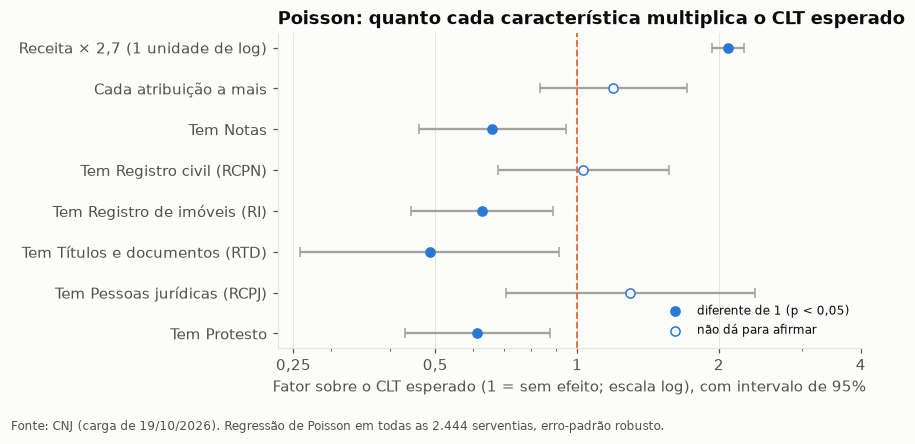

In [6]:
coef = rg.coeficientes_poisson(base)
nomes = {"log_receita": "Receita × 2,7 (1 unidade de log)", "n_atribuicoes": "Cada atribuição a mais",
         **{a: f"Tem {dados.NOMES_ATRIBUICOES[a]}" for a in dados.ATRIBUICOES}}
c = coef.drop("const").rename(index=nomes)
c["efeito_pct"] = c.fator - 1
display(g.tabela(c.reset_index(names="variável")[["variável", "fator", "fator_ic_inf", "fator_ic_sup", "efeito_pct", "p_valor"]],
                 {"fator": "num2", "fator_ic_inf": "num2", "fator_ic_sup": "num2", "efeito_pct": "pct", "p_valor": "num2"}))
dobro = 2 ** coef.loc["log_receita", "coef"] - 1
print(f"Receita 2 vezes maior → {g.pct(dobro)} mais CLT esperados (elasticidade {g.num(coef.loc['log_receita', 'coef'], 2)}), "
      f"com as atribuições fixas.")

fig, ax = plt.subplots(figsize=(8, 3.8))
cc = c.iloc[::-1]
y = np.arange(len(cc))
sig = cc.p_valor < 0.05
ax.errorbar(cc.fator, y, xerr=[cc.fator - cc.fator_ic_inf, cc.fator_ic_sup - cc.fator], fmt="none",
            ecolor=g.CINZA, elinewidth=1.5, capsize=3)
ax.scatter(cc.fator[sig], y[sig], color=g.AZUL["medio"], zorder=3, label="diferente de 1 (p < 0,05)")
ax.scatter(cc.fator[~sig], y[~sig], color=g.SUPERFICIE, edgecolor=g.AZUL["medio"], zorder=3, label="não dá para afirmar")
ax.axvline(1, color=g.CORES[1], linestyle="--", linewidth=1.2)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0,25", "0,5", "1", "2", "4"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(y, cc.index)
ax.set_xlabel("Fator sobre o CLT esperado (1 = sem efeito; escala log), com intervalo de 95%")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=8)
ax.set_title("Poisson: quanto cada característica multiplica o CLT esperado")
fig.tight_layout()
g.nota(fig, f"Fonte: CNJ (carga de 19/10/2026). Regressão de Poisson em todas as {g.num(len(base))} serventias, "
            "erro-padrão robusto.")
g.salvar(fig, "06_clt_poisson_fatores")
plt.show()

**Como ler.** Cada ponto é o fator; a linha cinza é o intervalo de 95%. Ponto à direita da linha tracejada: a característica aumenta o CLT esperado; à esquerda, diminui. Ponto vazio: o intervalo cruza o 1, e os dados não permitem afirmar o efeito.

**O que encontramos.**
- A **receita** é o que mais pesa: receita **2 vezes maior** dá **67% mais** empregados esperados (elasticidade 0,74). Como é menos que 100%, cartórios maiores têm **menos empregados por real** de receita (ganho de escala).
- Com a **mesma receita**, ter Notas, Registro de Imóveis, Títulos e Documentos ou Protesto está associado a **34% a 51% menos** empregados. Isso não quer dizer que essas atribuições "tiram" empregados: elas são as que rendem mais por ato, então, para a mesma receita, o cartório faz menos atos e precisa de menos gente.
- O número de atribuições, Registro Civil e Pessoas Jurídicas não têm efeito claro (intervalos largos que cruzam o 1).

**O que significa para o Prov. 227.** O passivo (e, portanto, a garantia exigida) não cresce na mesma proporção da receita: um cartório com o dobro da receita tem, em média, ≈ 1,7 vez os empregados. Para uma seguradora, a receita é um bom indicador do tamanho do risco, mas não um multiplicador direto.

**Limitações.** São associações dentro de MG, não causas. As atribuições aparecem juntas em muitos cartórios (por exemplo, RTD e RCPJ), o que alarga os intervalos.

### 6. Entrega: desenho da `gold.analise_clt_modelo`

A tabela que o pipeline vai gravar na Etapa 2 (função `src/analise/regressao.py: tabela_clt_modelo`): uma linha por serventia do recorte, com o CLT declarado, as previsões fora da amostra (região de fora) da floresta, do Poisson e da referência, e o resíduo da floresta.

In [7]:
analise_clt_modelo = rg.tabela_clt_modelo(base, prev)
print(f"gold.analise_clt_modelo (desenho): {g.num(len(analise_clt_modelo))} linhas, uma por serventia.")
display(analise_clt_modelo.dtypes.rename("tipo").to_frame().T)
display(g.tabela(analise_clt_modelo.head(3), {"receita_ref": "reais", "clt_declarado": "int", "clt_previsto_floresta": "num1",
                                              "clt_previsto_poisson": "num1", "clt_previsto_referencia": "num1",
                                              "residuo_floresta": "num1"}))

gold.analise_clt_modelo (desenho): 2.444 linhas, uma por serventia.


,cns,cod_ibge,regiao_intermediaria,receita_ref,n_atribuicoes,clt_declarado,clt_previsto_floresta,clt_previsto_poisson,clt_previsto_referencia,residuo_floresta,validacao
tipo,str,int64,str,float64,int64,float64,float64,float64,float64,float64,str


,cns,cod_ibge,regiao_intermediaria,receita_ref,n_atribuicoes,clt_declarado,clt_previsto_floresta,clt_previsto_poisson,clt_previsto_referencia,residuo_floresta,validacao
0,000059,3106705,Belo Horizonte,"R$ 6,0 mi",1,23,"19,6","17,0","13,0","3,4",regiao_intermediaria_fora
1,000091,3102605,Pouso Alegre,"R$ 386,3 mil",1,3,"4,8","4,3","3,0","-1,8",regiao_intermediaria_fora
2,000190,3162500,Barbacena,"R$ 9,4 mil",2,0,"1,2","0,2","0,0","-1,2",regiao_intermediaria_fora


**Para que serve no painel.** Mostrar, na página de qualidade, o quanto o modelo erra em MG (onde a resposta é conhecida) antes de usá-lo em outro estado. O total estimado de outro estado deve sair sempre com a faixa de ±10%.

## Parte (b) — De onde vem o passivo de cada serventia

### 7. Como o modelo calcula o passivo

**A pergunta.** O passivo de uma serventia é feito de quê?

**O método.** O pipeline calcula, para cada **vínculo** da RAIS 2025 (empregado CLT, com o salário de dezembro e os meses de casa), o custo de demiti-lo sem justa causa em 31/12/2025, como manda o art. 5º do Prov. 227. Depois tira o **passivo médio por vínculo** de uma **distribuição**: a do próprio município, se ele tem 20 vínculos ou mais (D-008); senão, a da região imediata do IBGE (D-022). O passivo da serventia é:

**passivo = CLT declarados ao CNJ × passivo médio por vínculo da distribuição**

Exemplo: uma serventia com 4 CLT num município cuja distribuição tem passivo médio de R$ 25 mil por vínculo tem passivo de 4 × 25 mil = R$ 100 mil.

O passivo médio por vínculo, por sua vez, depende do **salário** e do **tempo de casa** dos vínculos da distribuição. A seção 8 mostra as verbas; a seção 9 mede quanto da diferença entre serventias vem de cada parte.

In [8]:
medio = con.execute("SELECT * FROM gold.interno_passivo_municipio WHERE nivel = 'base'").df()
regioes = dict(con.execute("SELECT cod_ibge, regiao_imediata FROM silver.municipio_ibge").fetchall())
vinc = preparar_vinculos(dados.vinculos_rais(con), "dezembro", 1.0)   # premissas v2: dezembro, sem correção
dist = rg.distribuicao_usada(vinc, medio, regioes)
pb = sv[sv.passivo > 0].merge(dist, on="cod_ibge", how="left")
print(f"Serventias com passivo > 0: {g.num(len(pb))} (as outras {g.num(len(sv) - len(pb))} têm zero CLT ou CLT não informado).")
print(f"Vínculos da RAIS usados: {g.num(len(vinc))}. Distribuições usadas: "
      + "; ".join(f"{o}: {g.num(n)} municípios" for o, n in medio.origem_distribuicao.value_counts().items())
      + f"; {g.num(pb.chave_distribuicao.nunique())} distribuições diferentes.")
assert np.allclose(pb.passivo, pb.clt * pb.passivo_medio_vinculo)   # passivo = CLT × passivo médio por vínculo

Serventias com passivo > 0: 2.205 (as outras 320 têm zero CLT ou CLT não informado).
Vínculos da RAIS usados: 10.978. Distribuições usadas: regiao: 716 municípios; municipio: 135 municípios; 205 distribuições diferentes.


### 8. As verbas do passivo e quais crescem com o tempo de casa

**A pergunta.** Que parte do passivo depende do tempo de casa?

**O método.** Somamos cada verba de todos os vínculos de MG (função oficial `passivo_por_vinculo`, premissas v2, nível base). O aviso prévio tem 30 dias mais 3 por ano completo (Lei 12.506/2011); a multa de 40% incide sobre todos os depósitos do FGTS do contrato, que crescem com os meses de casa; as férias vencidas só existem para quem tem 1 ano ou mais.

In [9]:
p = resolver(estado.ler_semente(), "base")   # o passivo por vínculo não depende do peso das indeterminadas
verbas = pd.DataFrame([vars(passivo_por_vinculo(s, m, p)) for s, m in zip(vinc.salario, vinc.meses_servico)])
cols = {"aviso_previo": "Aviso prévio", "decimo_terceiro": "13º da projeção do aviso", "ferias": "Férias (com 1/3)",
        "multa_fgts": "Multa de 40% do FGTS", "fgts_rescisorio": "FGTS sobre a rescisão", "inss_patronal": "INSS patronal",
        "rat_fap": "RAT × FAP"}
comp = verbas[list(cols)].sum().rename(index=cols).to_frame("total")
comp["parte"] = comp.total / comp.total.sum()
comp["depende do tempo de casa"] = ["sim (30 dias + 3 por ano)", "sim (pela projeção do aviso)", "em parte (vencidas após 1 ano)",
                                    "sim (∝ meses de contrato)", "sim (sobre aviso e 13º)", "não", "não"]
display(g.tabela(comp.reset_index(names="verba"), {"total": "reais", "parte": "pct"}))
print(f"Passivo médio por vínculo em MG: {g.reais(verbas[list(cols)].sum(axis=1).mean())}; salário de dezembro mediano "
      f"{g.reais(vinc.salario.median())}; tempo de casa mediano {g.num(vinc.meses_servico.median())} meses.")

,verba,total,parte,depende do tempo de casa
0,Aviso prévio,"R$ 65,6 mi","24,9%",sim (30 dias + 3 por ano)
1,13º da projeção do aviso,"R$ 5,2 mi","2,0%",sim (pela projeção do aviso)
2,Férias (com 1/3),"R$ 58,0 mi","22,0%",em parte (vencidas após 1 ano)
3,Multa de 40% do FGTS,"R$ 127,7 mi","48,5%",sim (∝ meses de contrato)
4,FGTS sobre a rescisão,"R$ 5,7 mi","2,2%",sim (sobre aviso e 13º)
5,INSS patronal,"R$ 1,0 mi","0,4%",não
6,RAT × FAP,"R$ 52,4 mil","0,0%",não


Passivo médio por vínculo em MG: R$ 24,0 mil; salário de dezembro mediano R$ 2,7 mil; tempo de casa mediano 31 meses.


**Como ler.** A coluna "parte" diz quanto de todo o passivo de MG vem de cada verba.

**O que encontramos.**
- A **multa de 40% do FGTS** é quase **metade do passivo** (48,5%). Ela é proporcional ao salário **e** aos meses de contrato: um empregado com 10 anos de casa gera uma multa cerca de 10 vezes maior que um com 1 ano, com o mesmo salário.
- **Aviso prévio** (25%) e **férias** (22%) completam o resto; os encargos (FGTS, INSS e RAT sobre a rescisão) somam menos de 3%, porque incidem só sobre parte das verbas (premissas v2: o INSS não incide sobre o aviso nem sobre as férias indenizadas).
- Ou seja, **≈ 72% do passivo cresce com o tempo de casa**: a multa (48,5%), os dias de aviso acima de 30 (9,5%), as férias vencidas (12,5%) e o 13º da projeção do aviso (2,0%). Fora disso ficam os 30 dias de aviso de todo empregado (15,4%), as férias proporcionais (9,6%) e os encargos (2,6%).

**O que significa para o Prov. 227.** O passivo de um empregado antigo é muito maior que o de um novo com o mesmo salário. Cartórios com equipe estável (comum em serventias providas há muitos anos) têm passivo alto mesmo com salários modestos.

**Limitações.** O saldo do FGTS é estimado com o salário atual e sem juros (premissa `fator_correcao_saldo_fgts = 1`, `fonte: suposição`); a multa real pode ser maior ou menor.

### 9. Quanto da diferença vem da quantidade, do salário e do tempo de casa

**A pergunta.** Entre duas serventias, o que mais explica a diferença de passivo?

**O método.**
- **Log transforma produto em soma:** se passivo = CLT × médio, então log(passivo) = log(CLT) + log(médio). A **variância** (o quanto os valores se espalham em torno da média; para o log, quer dizer diferenças em %) de log(passivo) se divide entre as duas parcelas, mais a parte em que elas andam juntas (a covariância), que dividimos meio a meio.
- **Regressão log-log:** log(passivo) = b₀ + b₁·log(CLT) + b₂·log(salário médio) + b₃·log(tempo de casa médio), com o salário e o tempo médios **da distribuição que o modelo usou** para aquela serventia. Cada b é uma **elasticidade**: com b₂ = 1,1, salário médio 10% maior está associado a passivo ≈ 11% maior. O b₁ tem de dar 1, porque o passivo é proporcional ao CLT por construção (é uma conferência).
- **Divisão de Shapley:** o R² da regressão é dividido entre as três variáveis pela média do ganho de R² ao incluir cada uma, sobre todas as ordens possíveis de entrada. Exemplo com duas variáveis: se só A dá R² 0,6, só B dá 0,2 e as duas juntas dão 0,7, A recebe a média de 0,6 (entrando primeiro) e 0,5 (entrando depois de B), ou seja, 0,55; B recebe 0,15. As partes somam o R² total.
- **Validação em 10 dobras:** as serventias são divididas em 10 grupos; cada grupo é previsto por uma regressão ajustada nos outros 9. Serventias que usam a mesma distribuição ficam sempre no mesmo grupo, para a regressão não "ver" no treino o passivo médio que vai prever.

Variância de log(passivo) entre serventias: 1,25. Parte da quantidade (CLT): 79,3%; parte do passivo médio por vínculo: 20,7% (correlação entre os dois logs: 0,27).


,parte,elasticidade,ic_inf,ic_sup,parte da variância
0,Quantidade (CLT),"1,00","1,00","1,00","75,4%"
1,Salário médio,"1,15","1,13","1,17","18,0%"
2,Tempo de casa médio,"0,62","0,60","0,64","5,8%"


R² no ajuste: 0,992; R² fora da amostra (10 dobras por distribuição): 0,992; sem explicação: 0,8%.


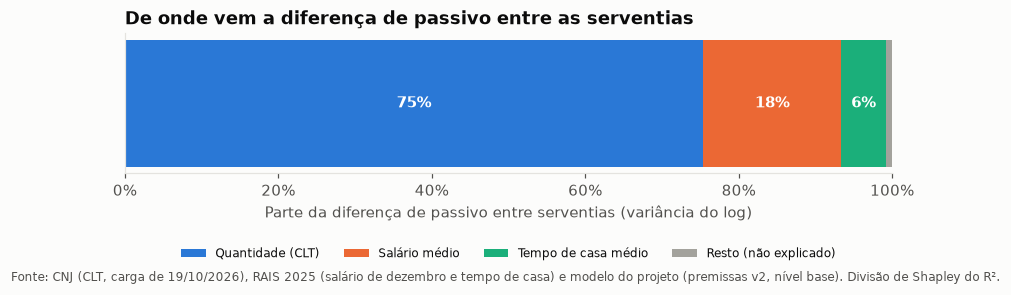

In [10]:
pv = rg.partes_variancia_log(pb.clt, pb.passivo_medio_vinculo)
print(f"Variância de log(passivo) entre serventias: {g.num(pv['variancia_total'], 2)}. Parte da quantidade (CLT): "
      f"{g.pct(pv['quantidade'])}; parte do passivo médio por vínculo: {g.pct(pv['passivo_medio_vinculo'])} "
      f"(correlação entre os dois logs: {g.num(pv['correlacao'], 2)}).")

reg_total = rg.regressao_loglog(pb, "passivo", ["clt", "salario_medio", "meses_medio"], grupos=pb.chave_distribuicao)
X = np.log(pb[["clt", "salario_medio", "meses_medio"]])
shap = rg.shapley_r2(X, np.log(pb.passivo))
rotulos = {"clt": "Quantidade (CLT)", "salario_medio": "Salário médio", "meses_medio": "Tempo de casa médio"}
tab = reg_total["coeficientes"].drop("const").rename(index=rotulos)
tab["parte da variância"] = shap.rename(index=rotulos)
display(g.tabela(tab.reset_index(names="parte"), {"elasticidade": "num2", "ic_inf": "num2", "ic_sup": "num2",
                                                   "parte da variância": "pct"}))
print(f"R² no ajuste: {g.num(reg_total['r2'], 3)}; R² fora da amostra (10 dobras por distribuição): "
      f"{g.num(reg_total['r2_validacao'], 3)}; sem explicação: {g.pct(1 - reg_total['r2_validacao'])}.")

fig, ax = plt.subplots(figsize=(9, 2.4))
esq = 0
for (nome, v), cor in zip(list(shap.rename(index=rotulos).items()) + [("Resto (não explicado)", 1 - reg_total["r2"])],
                          [g.AZUL["medio"], g.CORES[1], g.CORES[2], g.CINZA]):
    ax.barh(0, v, left=esq, color=cor, height=0.5, label=nome)
    if v > 0.03:
        ax.text(esq + v / 2, 0, g.pct(v, 0), ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    esq += v
ax.set_xlim(0, 1)
ax.set_yticks([])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: g.pct(v, 0)))
ax.set_xlabel("Parte da diferença de passivo entre serventias (variância do log)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=4, fontsize=8)
ax.grid(visible=False)
ax.set_title("De onde vem a diferença de passivo entre as serventias")
g.nota(fig, "Fonte: CNJ (CLT, carga de 19/10/2026), RAIS 2025 (salário de dezembro e tempo de casa) e modelo do projeto "
            "(premissas v2, nível base). Divisão de Shapley do R².")
fig.subplots_adjust(bottom=0.35)
g.salvar(fig, "06_passivo_decomposicao")
plt.show()

**Como ler.** A barra divide a diferença de passivo entre as serventias (no log, isto é, em %) entre as três partes. A tabela traz as elasticidades com o intervalo de 95%.

**O que encontramos.**
- A **quantidade de empregados** explica **≈ 75% a 79%** da diferença de passivo entre serventias (75% pela divisão de Shapley da regressão; 79% pela divisão direta da variância do log). Um cartório tem mais passivo, antes de tudo, porque tem mais gente.
- O **salário médio** explica **18%** e o **tempo de casa médio**, **6%**. A regressão explica 99,2% da diferença, tanto no ajuste quanto fora da amostra (99,2%): o modelo não está "decorando".
- Elasticidades: salário médio 10% maior está associado a passivo **≈ 11,5% maior**; tempo de casa médio 10% maior, a passivo **≈ 6% maior**.
- Isso **não contradiz** a seção 8 (≈ 72% do passivo cresce com o tempo de casa): lá a pergunta era "de que é feito o passivo"; aqui é "o que muda de um cartório para outro". O tempo de casa **médio** varia pouco entre as distribuições usadas (municípios e regiões), então pesa pouco na diferença entre cartórios.

**O que significa para o Prov. 227.** Para estimar o passivo de um cartório (ou de outro estado), o mais importante é acertar o **número de empregados**; o salário vem em segundo. É por isso que a parte (a) importa: o erro de ±10% no total de CLT vira, quase direto, ±10% no passivo.

**Limitações.** O salário e o tempo de casa são os da **distribuição** (município ou região), não os da serventia: a RAIS não diz em qual cartório cada vínculo trabalha. Por isso o modelo não enxerga a diferença de salário entre dois cartórios do mesmo município, e a parte do salário e do tempo de casa está **subestimada** em relação à realidade.

### 10. O que o salário e o tempo de casa não explicam (resíduos)

**A pergunta.** O passivo médio por vínculo é só "salário × tempo de casa"?

**O método.** Regressão log-log do passivo médio por vínculo no salário médio e no tempo de casa médio da distribuição, com a mesma validação em 10 dobras. O **resíduo** é o erro da previsão fora da amostra, em %: real ÷ previsto − 1. No gráfico, cada ponto é uma distribuição (um município próprio ou uma região imediata), não uma serventia.

,variável,elasticidade,ic_inf,ic_sup
0,const,"-1,92","-2,05","-1,78"
1,salario_medio,"1,15","1,13","1,17"
2,meses_medio,"0,62","0,60","0,64"


log(passivo médio por vínculo) pelo log do salário e do tempo de casa: R² 0,937; fora da amostra 0,936.


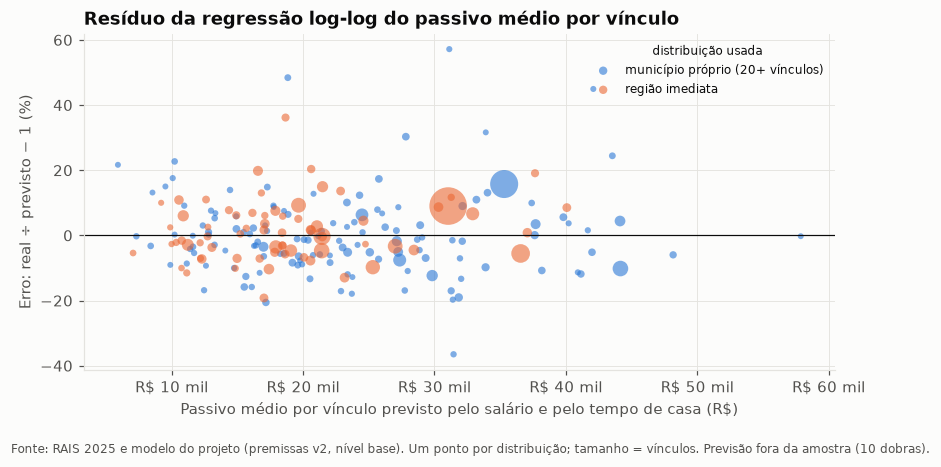

Erro absoluto mediano por distribuição: 6,4%; maior: 57,2%.


In [11]:
reg_medio = rg.regressao_loglog(pb, "passivo_medio_vinculo", ["salario_medio", "meses_medio"], grupos=pb.chave_distribuicao)
display(g.tabela(reg_medio["coeficientes"].reset_index(names="variável"), {"elasticidade": "num2", "ic_inf": "num2", "ic_sup": "num2"}))
print(f"log(passivo médio por vínculo) pelo log do salário e do tempo de casa: R² {g.num(reg_medio['r2'], 3)}; "
      f"fora da amostra {g.num(reg_medio['r2_validacao'], 3)}.")
# uma linha por distribuição (município ou região), para não contar a mesma distribuição várias vezes
d = pb.assign(res=reg_medio["residuo_validacao"], prev=reg_medio["previsto_validacao"]).groupby("chave_distribuicao").agg(
    origem=("origem_distribuicao", "first"), res=("res", "first"), prev=("prev", "first"), n=("n_vinculos_distribuicao", "first"))
fig, ax = plt.subplots(figsize=(8, 4))
for (orig, rot), cor in zip([("municipio", "município próprio (20+ vínculos)"), ("regiao", "região imediata")],
                            [g.AZUL["medio"], g.CORES[1]]):
    x = d[d.origem == orig]
    ax.scatter(np.exp(x.prev), 100 * (np.exp(x.res) - 1), s=10 + x.n / 4, alpha=0.6, color=cor, label=rot, edgecolor="none")
ax.axhline(0, color=g.TEXTO, linewidth=0.8)
g.eixo_reais(ax, "x")
ax.set_xlabel("Passivo médio por vínculo previsto pelo salário e pelo tempo de casa (R$)")
ax.set_ylabel("Erro: real ÷ previsto − 1 (%)")
leg = ax.legend(loc="upper right", fontsize=8, title="distribuição usada", title_fontsize=8)
for h in leg.legend_handles:
    h.set_sizes([30])
ax.set_title("Resíduo da regressão log-log do passivo médio por vínculo")
fig.tight_layout()
g.nota(fig, "Fonte: RAIS 2025 e modelo do projeto (premissas v2, nível base). Um ponto por distribuição; tamanho = vínculos. "
            "Previsão fora da amostra (10 dobras).")
g.salvar(fig, "06_passivo_residuos")
plt.show()
print(f"Erro absoluto mediano por distribuição: {g.pct(np.median(np.abs(np.exp(d.res) - 1)))}; maior: "
      f"{g.pct(np.max(np.abs(np.exp(d.res) - 1)))}.")

**Como ler.** Pontos perto da linha zero: o salário e o tempo de casa médios explicam bem o passivo médio daquela distribuição.

**O que encontramos.**
- O salário médio e o tempo de casa médio explicam **94%** da diferença do passivo médio por vínculo entre as distribuições (R² 0,937; 0,936 fora da amostra). O erro mediano é de **6,4%**.
- Os erros grandes (até 57%) aparecem nos **municípios próprios** pequenos (os pontos azuis menores), onde poucos vínculos com muito tempo de casa ou salário alto mudam a média. As **regiões imediatas** (laranja), com mais vínculos, ficam mais perto de zero.
- A elasticidade do salário (1,15) passa de 1, embora o passivo de um vínculo seja proporcional ao salário dele: onde o salário médio é maior, os vínculos de salário alto também tendem a ter mais tempo de casa, e a média de "salário × tempo" cresce mais que o produto das médias.

**O que significa para o Prov. 227.** A média do salário e do tempo de casa resume bem o passivo de uma região. Para outro estado, bastaria a RAIS (que é nacional) para o passivo médio por vínculo, e o CLT estimado da parte (a) para a quantidade.

**Limitações.** O resíduo não é erro do cálculo do passivo (que é feito vínculo a vínculo, pela norma); é o que a média de salário e tempo de casa não captura (a dispersão e a forma da distribuição).

## 11. Resumo dos achados

1. **A receita estima bem os empregados.** A floresta aleatória erra em média 1,86 empregado por serventia numa região que não viu (20% menos que a referência; R² 0,75), igual ao teste T1.
2. **Para um estado inteiro, ±10% no total.** O erro de uma região chega a 26%, mas, somando as 13 regiões previstas de fora, o total de MG fica 2,5% abaixo do declarado. Publicar só totais estaduais estimados, com ±10%.
3. **Ganho de escala.** Receita 2 vezes maior dá ≈ 67% mais empregados; para a mesma receita, cartórios com Notas, Imóveis, Títulos ou Protesto têm 34% a 51% menos empregados.
4. **O passivo é, antes de tudo, quantidade.** O número de empregados explica ≈ 75% a 79% da diferença de passivo entre serventias; o salário médio, 18%; o tempo de casa médio, 6%.
5. **Metade do passivo é a multa do FGTS.** ≈ 72% do passivo cresce com o tempo de casa; o tempo de casa pesa muito no valor, mas pouco na diferença entre cartórios.

**Entrega:** desenho da `gold.analise_clt_modelo` (`src/analise/regressao.py: tabela_clt_modelo`, com teste em `tests/test_analise_modelos.py`).

**Para o cálculo do painel:** nada aqui muda os 10 números. Para a expansão a outros estados: floresta por serventia, total estadual com ±10%, e validação num estado que tenha a contagem do CNJ antes de publicar.

> **Atualização (2026-10-28, D-046): premissas v3.** As saídas deste notebook são da carga com as premissas v2. Desde a D-046, a chance de déficit e a parte descoberta vêm da capacidade de pagar do titular (M1, notebook 10), e não mais de suposição. Os números 1 a 5 e o 10 não mudaram; o déficit, a IS e o prêmio caíram 7,5% (prêmio de R$ 368,7 mil para R$ 341,1 mil), e a contagem "com déficit" foi de ≈ 486 para ≈ 148. O que este notebook diz sobre dados, classes, passivo e universo continua valendo; os valores de déficit e prêmio atuais estão no `notebooks/09_conclusoes_lacunas.ipynb`. A D-046 também manteve o valor declarado nos semestres com salto grosseiro (com aviso no pipeline e sensibilidade "sem os saltos") e deixou os dados como os de 17 e 18/10.